Paths and reusable definitions were refactored. Stored outputs below are historical, not a fresh execution. See `docs/WORKFLOW.md` at the repository root before rerunning; several stages overwrite results or append Optuna trials.


In [ ]:
# Locate this checkout from the repository root or any notebook subdirectory.
from pathlib import Path
import sys

_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
              if (p / "src" / "steam_recommender" / "paths.py").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside the repository checkout.")
sys.path.insert(0, str(_root / "src"))
from steam_recommender import paths as _paths
if Path(_paths.__file__).resolve() != (_root / "src/steam_recommender/paths.py").resolve():
    raise RuntimeError("A different checkout is cached; restart the kernel.")
from steam_recommender.paths import project_root, project_path


In [1]:
# =========================
# FINAL TEST EVALUATION — ALS-constant (gamma)
# =========================

import os
import sys
import numpy as np
import pandas as pd
from tqdm.auto import tqdm


# =========================
# PATHS
# =========================


data_dir = os.path.join(str(project_path("data/processed")))
optuna_results_dir = os.path.join(str(project_path("results/optuna")))
final_results_dir = os.path.join(str(project_path("results/final")))

os.makedirs(final_results_dir, exist_ok=True)

# =========================
# IMPORT FROM PIPELINE
# =========================

from steam_recommender.als import ALSPipeline
from steam_recommender.confidence import linear_signal, log_signal, log_saturated_signal, make_log_inside_beta_signal, make_constant_signal
from steam_recommender.metrics import precision_at_k, recall_at_k, ndcg_at_k, coverage_at_k, delta_gap


# =========================
# FILE PATHS
# =========================

best_configs_path = os.path.join(
    optuna_results_dir,
    "best_als_configs.csv"
)

test_metrics_path = os.path.join(
    final_results_dir,
    "test_metrics_by_seed.csv"
)

per_user_ndcg_path = os.path.join(
    final_results_dir,
    "per_user_ndcg.csv"
)


# =========================
# LOAD DATA
# =========================

train_val_df = pd.read_csv(
    os.path.join(data_dir, "users_items_filtered_train_val.csv")
)

test_df = pd.read_csv(
    os.path.join(data_dir, "users_items_filtered_test.csv")
)

best_configs = pd.read_csv(best_configs_path)


# Typy jako stringi — spójnie z pipeline
for df in [train_val_df, test_df]:
    df["user_id"] = df["user_id"].astype(str)
    df["item_id"] = df["item_id"].astype(str)

display(best_configs)

print("train_val_df:", train_val_df.shape)
print("test_df:", test_df.shape)

C:\Users\misie\AppData\Local\Temp\ipykernel_21308\1337506588.py:70: DtypeWarning: Columns (0: user_id) have mixed types. Specify dtype option on import or set low_memory=False.
  train_val_df = pd.read_csv(


,model,function,factors,iterations,alpha,beta,gamma,regularization,validation_ndcg,study_name,n_trials
0,ALS-linear,linear,80,30,9.948124e-07,NaN,NaN,0.003588,0.248913,als_linear,150
1,ALS-log,log,24,30,5.713901e-04,NaN,NaN,0.130920,0.261320,als_log,150
2,ALS-log-saturation,log_saturation,24,30,2.439038e-02,NaN,NaN,0.169714,0.261400,als_log_saturation,150
3,ALS-log-inside-beta,log_inside_beta,48,30,3.891845e-01,108.283984,NaN,0.010565,0.275349,als_log_inside_beta,150
4,ALS-constant,constant,48,30,1.000000e+00,NaN,2.364168,0.057607,0.280063,als_constant,150


train_val_df: (4591379, 4)
test_df: (541231, 4)


In [2]:
# =========================
# HELPERS
# =========================

from steam_recommender.confidence import get_signal_fn


function_labels = {
    "popular": "popularność",
    "linear": "liniowa",
    "log": "logarytmiczna",
    "log_saturation": "logarytmiczna z saturacją",
    "log_inside_beta": "logarytmiczna z przesunięciem β",
    "constant": "stała (γ)",
}


# =========================
# FINAL EVALUATION SETTINGS
# =========================

K = 10
seeds = [0, 1, 2, 3, 4]

num_threads = 8

TARGET_MODEL = "ALS-constant"


In [3]:
# =========================
# FINAL TEST EVALUATION — ALS-constant only
# =========================

constant_configs = best_configs[best_configs["model"] == TARGET_MODEL]

if len(constant_configs) != 1:
    raise ValueError(
        f"Expected exactly 1 config for {TARGET_MODEL}, "
        f"got {len(constant_configs)}."
    )

metric_rows = []
per_user_rows = []

for _, config in constant_configs.iterrows():
    model_name = config["model"]
    function_name = config["function"]

    factors = int(config["factors"])
    iterations = int(config["iterations"])
    alpha = float(config["alpha"])

    beta = config["beta"] if "beta" in config and not pd.isna(config["beta"]) else None
    gamma = config["gamma"] if "gamma" in config and not pd.isna(config["gamma"]) else None

    regularization = float(config["regularization"])

    signal_fn = get_signal_fn(function_name, beta=beta, gamma=gamma)

    print("\n=========================")
    print(f"Model: {model_name}")
    print(
        f"function={function_name}, "
        f"factors={factors}, iterations={iterations}, "
        f"alpha={alpha}, gamma={gamma}, reg={regularization}"
    )

    for seed in tqdm(seeds, desc=model_name):
        pipeline = ALSPipeline(
            factors=factors,
            iterations=iterations,
            alpha=alpha,
            regularization=regularization,
            random_state=seed,
            signal_strength_fn=signal_fn,
            num_threads=num_threads,
        )

        results, recommendations, user_ndcg = pipeline.refit_full_and_test(
            train_df=train_val_df,
            test_df=test_df,
            K=K,
            return_per_user=True,
            verbose=False,
        )

        metric_row = {
            "model": model_name,
            "function": function_name,
            "function_label": function_labels.get(function_name, function_name),
            "seed": seed,
            "factors": factors,
            "iterations": iterations,
            "alpha": alpha,
            "beta": beta,
            "gamma": gamma,
            "regularization": regularization,
        }

        metric_row.update(results)
        metric_rows.append(metric_row)

        for user_id, ndcg_value in user_ndcg.items():
            per_user_rows.append({
                "model": model_name,
                "function": function_name,
                "function_label": function_labels.get(function_name, function_name),
                "seed": seed,
                "user_id": user_id,
                f"ndcg@{K}": ndcg_value,
            })


constant_metrics_df = pd.DataFrame(metric_rows)
constant_per_user_df = pd.DataFrame(per_user_rows)

display(constant_metrics_df)
print("constant_per_user_df:", constant_per_user_df.shape)


Model: ALS-constant
function=constant, factors=48, iterations=30, alpha=1.0, gamma=2.364168339566743, reg=0.0576073731357379


ALS-constant:   0%|          | 0/5 [00:00<?, ?it/s]

d:\Anaconda\envs\recommender\Lib\site-packages\implicit\cpu\als.py:95: RuntimeWarning: Intel MKL BLAS is configured to use 8 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'MKL_NUM_THREADS=1' or by callng 'threadpoolctl.threadpool_limits(1, "blas")'. Having MKL use a threadpool can lead to severe performance issues
  check_blas_config()


  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

,model,function,function_label,seed,factors,iterations,alpha,beta,gamma,regularization,precision@10,recall@10,ndcg@10,coverage@10,delta_gap@10,diversity@10,users_evaluated
0,ALS-constant,constant,stała (γ),0,48,30,1.0,None,2.364168,0.057607,0.197962,0.337162,0.356912,0.137965,0.419833,0.774147,62944
1,ALS-constant,constant,stała (γ),1,48,30,1.0,None,2.364168,0.057607,0.197607,0.336668,0.355760,0.137095,0.420752,0.761846,62944
2,ALS-constant,constant,stała (γ),2,48,30,1.0,None,2.364168,0.057607,0.197782,0.336980,0.356805,0.137747,0.421280,0.763406,62944
3,ALS-constant,constant,stała (γ),3,48,30,1.0,None,2.364168,0.057607,0.197866,0.337196,0.356728,0.136986,0.422081,0.746301,62944
4,ALS-constant,constant,stała (γ),4,48,30,1.0,None,2.364168,0.057607,0.197835,0.336916,0.356502,0.137421,0.420939,0.762149,62944


constant_per_user_df: (314720, 6)


In [5]:
# =========================
# MERGE INTO EXISTING TEST RESULTS
# =========================

test_metrics_df = pd.read_csv(test_metrics_path)
per_user_ndcg_df = pd.read_csv(per_user_ndcg_path)

# per_user user_id musi być stringiem — inaczej po round-tripie
# przez CSV zrobi się int i merge z nowymi wierszami się rozjedzie
per_user_ndcg_df["user_id"] = per_user_ndcg_df["user_id"].astype(str)
constant_per_user_df["user_id"] = constant_per_user_df["user_id"].astype(str)

# nowa kolumna hiperparametru dla starych wierszy
if "gamma" not in test_metrics_df.columns:
    test_metrics_df["gamma"] = pd.NA

# upsert — usuń ewentualne poprzednie uruchomienie tej komórki
test_metrics_df = test_metrics_df[test_metrics_df["model"] != TARGET_MODEL]
per_user_ndcg_df = per_user_ndcg_df[per_user_ndcg_df["model"] != TARGET_MODEL]

test_metrics_df = pd.concat(
    [test_metrics_df, constant_metrics_df],
    ignore_index=True
)

per_user_ndcg_df = pd.concat(
    [per_user_ndcg_df, constant_per_user_df],
    ignore_index=True
)

test_metrics_df.to_csv(test_metrics_path, index=False)
per_user_ndcg_df.to_csv(per_user_ndcg_path, index=False)

print(f"Saved test metrics to: {test_metrics_path}")
print(f"Saved per-user NDCG to: {per_user_ndcg_path}")

print("\nShapes:")
print("test_metrics_df:", test_metrics_df.shape)
print("per_user_ndcg_df:", per_user_ndcg_df.shape)

print("\nModels present:")
print(test_metrics_df["model"].value_counts())

Saved test metrics to: D:\Studiowe\Licencjat\modele\final_results\test_metrics_by_seed.csv
Saved per-user NDCG to: D:\Studiowe\Licencjat\modele\final_results\per_user_ndcg.csv

Shapes:
test_metrics_df: (26, 17)
per_user_ndcg_df: (1636544, 6)

Models present:
model
ALS-linear             5
ALS-log                5
ALS-log-saturation     5
ALS-log-inside-beta    5
ALS-constant           5
Popular                1
Name: count, dtype: int64


In [6]:
# =========================
# SUMMARY: TEST METRICS MEAN ± STD
# =========================

metric_cols = [
    f"precision@{K}",
    f"recall@{K}",
    f"ndcg@{K}",
    f"coverage@{K}",
    f"delta_gap@{K}",
    f"diversity@{K}",
    "users_evaluated",
]

summary_rows = []

for (model_name, function_name), group in test_metrics_df.groupby(["model", "function"]):
    row = {
        "model": model_name,
        "function": function_name,
        "function_label": group["function_label"].iloc[0],
        "n_runs": group["seed"].notna().sum(),
    }

    for metric in metric_cols:
        row[f"{metric}_mean"] = group[metric].mean()
        row[f"{metric}_std"] = group[metric].std(ddof=1)

    summary_rows.append(row)

test_summary_df = pd.DataFrame(summary_rows)

function_order = [
    "popular",
    "constant",
    "linear",
    "log",
    "log_saturation",
    "log_inside_beta",
]

test_summary_df["function_order"] = test_summary_df["function"].map(
    {name: i for i, name in enumerate(function_order)}
)

test_summary_df = (
    test_summary_df
    .sort_values("function_order")
    .drop(columns=["function_order"])
    .reset_index(drop=True)
)

display(test_summary_df)


# =========================
# PRETTY TABLE: MEAN ± STD
# =========================

pretty_rows = []

for _, row in test_summary_df.iterrows():
    pretty_row = {
        "model": row["model"],
        "function": row["function_label"],
    }

    for metric in metric_cols:
        mean = row[f"{metric}_mean"]
        std = row[f"{metric}_std"]

        if pd.isna(mean):
            pretty_row[metric] = "NA"
        elif row["function"] == "popular":
            # Popular ma pojedynczy wynik, więc bez std
            if metric == "users_evaluated":
                pretty_row[metric] = f"{mean:.0f}"
            else:
                pretty_row[metric] = f"{mean:.4f}"
        else:
            if metric == "users_evaluated":
                pretty_row[metric] = f"{mean:.0f} ± {std:.0f}"
            else:
                pretty_row[metric] = f"{mean:.4f} ± {std:.4f}"

    pretty_rows.append(pretty_row)

pretty_test_summary = pd.DataFrame(pretty_rows)

display(pretty_test_summary)

summary_path = os.path.join(final_results_dir, "test_summary.csv")
test_summary_df.to_csv(summary_path, index=False)
print(f"Saved summary to: {summary_path}")

,model,function,function_label,n_runs,precision@10_mean,precision@10_std,recall@10_mean,recall@10_std,ndcg@10_mean,ndcg@10_std,coverage@10_mean,coverage@10_std,delta_gap@10_mean,delta_gap@10_std,diversity@10_mean,diversity@10_std,users_evaluated_mean,users_evaluated_std
0,Popular,popular,popularność,0,0.096519,NaN,0.178252,NaN,0.185480,NaN,0.008698,NaN,1.423258,NaN,NaN,NaN,62944.0,NaN
1,ALS-constant,constant,stała (γ),5,0.197810,0.000131,0.336984,0.000213,0.356542,0.000462,0.137443,0.000417,0.420977,0.000817,0.761570,0.009939,62944.0,0.0
2,ALS-linear,linear,liniowa,5,0.184100,0.000260,0.264170,0.000452,0.329930,0.000523,0.117786,0.000694,-0.211241,0.001607,0.785433,0.006251,62944.0,0.0
3,ALS-log,log,logarytmiczna,5,0.180967,0.000103,0.301856,0.000173,0.335613,0.000295,0.076169,0.000250,0.543323,0.000807,0.596301,0.015880,62944.0,0.0
4,ALS-log-saturation,log_saturation,logarytmiczna z saturacją,5,0.180868,0.000166,0.301907,0.000302,0.335418,0.000484,0.076104,0.000172,0.544328,0.000893,0.594833,0.015152,62944.0,0.0
5,ALS-log-inside-beta,log_inside_beta,logarytmiczna z przesunięciem β,5,0.195639,0.000180,0.333795,0.000334,0.351690,0.000352,0.131333,0.000866,0.419129,0.002309,0.731420,0.017398,62944.0,0.0


,model,function,precision@10,recall@10,ndcg@10,coverage@10,delta_gap@10,diversity@10,users_evaluated
0,Popular,popularność,0.0965,0.1783,0.1855,0.0087,1.4233,NA,62944
1,ALS-constant,stała (γ),0.1978 ± 0.0001,0.3370 ± 0.0002,0.3565 ± 0.0005,0.1374 ± 0.0004,0.4210 ± 0.0008,0.7616 ± 0.0099,62944 ± 0
2,ALS-linear,liniowa,0.1841 ± 0.0003,0.2642 ± 0.0005,0.3299 ± 0.0005,0.1178 ± 0.0007,-0.2112 ± 0.0016,0.7854 ± 0.0063,62944 ± 0
3,ALS-log,logarytmiczna,0.1810 ± 0.0001,0.3019 ± 0.0002,0.3356 ± 0.0003,0.0762 ± 0.0003,0.5433 ± 0.0008,0.5963 ± 0.0159,62944 ± 0
4,ALS-log-saturation,logarytmiczna z saturacją,0.1809 ± 0.0002,0.3019 ± 0.0003,0.3354 ± 0.0005,0.0761 ± 0.0002,0.5443 ± 0.0009,0.5948 ± 0.0152,62944 ± 0
5,ALS-log-inside-beta,logarytmiczna z przesunięciem β,0.1956 ± 0.0002,0.3338 ± 0.0003,0.3517 ± 0.0004,0.1313 ± 0.0009,0.4191 ± 0.0023,0.7314 ± 0.0174,62944 ± 0


Saved summary to: D:\Studiowe\Licencjat\modele\final_results\test_summary.csv


In [7]:
# =========================
# PRETTY TABLE: MEAN ± STD
# =========================

pretty_rows = []

for _, row in test_summary_df.iterrows():
    pretty_row = {
        "model": row["model"],
        "function": row["function_label"],
    }

    for metric in metric_cols:
        mean = row[f"{metric}_mean"]
        std = row[f"{metric}_std"]

        if pd.isna(mean):
            pretty_row[metric] = "NA"
        elif row["function"] == "popular":
            # Popular ma pojedynczy wynik, więc bez std
            if metric == "users_evaluated":
                pretty_row[metric] = f"{mean:.0f}"
            else:
                pretty_row[metric] = f"{mean:.4f}"
        else:
            if metric == "users_evaluated":
                pretty_row[metric] = f"{mean:.0f} ± {std:.0f}"
            else:
                pretty_row[metric] = f"{mean:.4f} ± {std:.4f}"

    pretty_rows.append(pretty_row)

pretty_test_summary = pd.DataFrame(pretty_rows)

display(pretty_test_summary)


# =========================
# SAVE SUMMARY
# =========================

summary_path = os.path.join(final_results_dir, "test_summary.csv")
pretty_summary_path = os.path.join(final_results_dir, "test_summary_pretty.csv")

test_summary_df.to_csv(summary_path, index=False)
pretty_test_summary.to_csv(
    pretty_summary_path,
    index=False,
    encoding="utf-8-sig"
)

print(f"Saved summary to: {summary_path}")
print(f"Saved pretty summary to: {pretty_summary_path}")

,model,function,precision@10,recall@10,ndcg@10,coverage@10,delta_gap@10,diversity@10,users_evaluated
0,Popular,popularność,0.0965,0.1783,0.1855,0.0087,1.4233,NA,62944
1,ALS-constant,stała (γ),0.1978 ± 0.0001,0.3370 ± 0.0002,0.3565 ± 0.0005,0.1374 ± 0.0004,0.4210 ± 0.0008,0.7616 ± 0.0099,62944 ± 0
2,ALS-linear,liniowa,0.1841 ± 0.0003,0.2642 ± 0.0005,0.3299 ± 0.0005,0.1178 ± 0.0007,-0.2112 ± 0.0016,0.7854 ± 0.0063,62944 ± 0
3,ALS-log,logarytmiczna,0.1810 ± 0.0001,0.3019 ± 0.0002,0.3356 ± 0.0003,0.0762 ± 0.0003,0.5433 ± 0.0008,0.5963 ± 0.0159,62944 ± 0
4,ALS-log-saturation,logarytmiczna z saturacją,0.1809 ± 0.0002,0.3019 ± 0.0003,0.3354 ± 0.0005,0.0761 ± 0.0002,0.5443 ± 0.0009,0.5948 ± 0.0152,62944 ± 0
5,ALS-log-inside-beta,logarytmiczna z przesunięciem β,0.1956 ± 0.0002,0.3338 ± 0.0003,0.3517 ± 0.0004,0.1313 ± 0.0009,0.4191 ± 0.0023,0.7314 ± 0.0174,62944 ± 0


Saved summary to: D:\Studiowe\Licencjat\modele\final_results\test_summary.csv
Saved pretty summary to: D:\Studiowe\Licencjat\modele\final_results\test_summary_pretty.csv


## Wilcoxon

In [10]:
# =========================
# STATISTICAL TESTS — PAIRED WILCOXON
# (5 wariantów ALS, w tym constant)
# =========================

import os
import itertools
import numpy as np
import pandas as pd

from scipy.stats import wilcoxon


# =========================
# PATHS
# =========================


final_results_dir = os.path.join(str(project_path("results/final")))

per_user_ndcg_path = os.path.join(
    final_results_dir,
    "per_user_ndcg.csv"
)

wilcoxon_results_path = os.path.join(
    final_results_dir,
    "wilcoxon_holm_results.csv"
)

wilcoxon_matrix_path = os.path.join(
    final_results_dir,
    "wilcoxon_holm_pvalue_matrix.csv"
)


# =========================
# LOAD DATA
# =========================

per_user_df = pd.read_csv(per_user_ndcg_path)

display(per_user_df.head())
print("per_user_df:", per_user_df.shape)

print(per_user_df["model"].value_counts())


# =========================
# FILTER ALS MODELS
# =========================

als_functions = [
    "constant",
    "linear",
    "log",
    "log_saturation",
    "log_inside_beta",
]

als_df = per_user_df[
    per_user_df["function"].isin(als_functions)
].copy()

# Upewniamy się, że user_id jest stringiem
als_df["user_id"] = als_df["user_id"].astype(str)

ndcg_col = "ndcg@10"

# sanity check — każdy wariant musi mieć te same seedy
print(
    als_df.groupby("function")["seed"].nunique()
)

,model,function,function_label,seed,user_id,ndcg@10
0,ALS-linear,linear,liniowa,0.0,--000--,0.000000
1,ALS-linear,linear,liniowa,0.0,--ace--,0.098039
2,ALS-linear,linear,liniowa,0.0,--ionex--,0.000000
3,ALS-linear,linear,liniowa,0.0,-2SV-vuLB-Kg,0.000000
4,ALS-linear,linear,liniowa,0.0,-404PageNotFound-,0.630043


per_user_df: (1636544, 6)
model
ALS-linear             314720
ALS-log                314720
ALS-log-saturation     314720
ALS-log-inside-beta    314720
ALS-constant           314720
Popular                 62944
Name: count, dtype: int64
function
constant           5
linear             5
log                5
log_inside_beta    5
log_saturation     5
Name: seed, dtype: int64


In [11]:
# =========================
# HOLM-BONFERRONI CORRECTION
# =========================

from steam_recommender.statistics import holm_bonferroni


In [14]:
# =========================
# GUARD: rebuild matrix if missing
# =========================

if "user_model_matrix" not in globals():
    print("user_model_matrix not found — rebuilding from per_user_ndcg.csv")

    per_user_df = pd.read_csv(per_user_ndcg_path)

    als_df = per_user_df[
        per_user_df["function"].isin(als_functions)
    ].copy()

    als_df["user_id"] = als_df["user_id"].astype(str)

    per_user_mean = (
        als_df
        .groupby(["function", "function_label", "user_id"], as_index=False)[ndcg_col]
        .mean()
    )

    user_model_matrix = per_user_mean.pivot(
        index="user_id",
        columns="function",
        values=ndcg_col
    ).dropna(subset=als_functions)

    print("user_model_matrix:", user_model_matrix.shape)

# =========================
# PAIRED WILCOXON TESTS
# =========================

model_pairs = list(itertools.combinations(als_functions, 2))

print(f"Number of pairwise comparisons: {len(model_pairs)}")

rows = []

for model_a, model_b in model_pairs:
    a = user_model_matrix[model_a]
    b = user_model_matrix[model_b]

    diff = b - a  # dodatnie = model_b lepszy od model_a

    # Jeśli wszystkie różnice są zerowe, scipy może zwrócić błąd.
    if np.allclose(diff, 0):
        statistic = np.nan
        p_value = 1.0
    else:
        test_result = wilcoxon(
            b,
            a,
            alternative="two-sided",
            zero_method="wilcox",
            correction=False,
            mode="auto",
        )

        statistic = test_result.statistic
        p_value = test_result.pvalue

    rows.append({
        "model_a": model_a,
        "model_b": model_b,
        "comparison": f"{model_a} vs {model_b}",
        "n_users": len(diff),
        "wilcoxon_statistic": statistic,
        "p_value_raw": p_value,

        # effect size jako mediana różnicy per-user NDCG
        # dodatnia wartość oznacza przewagę model_b nad model_a
        "median_difference_b_minus_a": float(np.median(diff)),
        "mean_difference_b_minus_a": float(np.mean(diff)),

        "model_a_mean_ndcg": float(a.mean()),
        "model_b_mean_ndcg": float(b.mean()),
    })

wilcoxon_results = pd.DataFrame(rows)

# Holm-Bonferroni
wilcoxon_results["p_value_holm"] = holm_bonferroni(
    wilcoxon_results["p_value_raw"].values
)

wilcoxon_results["significant_0.05"] = (
    wilcoxon_results["p_value_holm"] < 0.05
)

wilcoxon_results = wilcoxon_results.sort_values(
    "p_value_raw"
).reset_index(drop=True)

display(wilcoxon_results)

wilcoxon_results.to_csv(wilcoxon_results_path, index=False)

print(f"Saved Wilcoxon results to: {wilcoxon_results_path}")

user_model_matrix not found — rebuilding from per_user_ndcg.csv
user_model_matrix: (62944, 5)
Number of pairwise comparisons: 10


,model_a,model_b,comparison,n_users,wilcoxon_statistic,p_value_raw,median_difference_b_minus_a,mean_difference_b_minus_a,model_a_mean_ndcg,model_b_mean_ndcg,p_value_holm,significant_0.05
0,constant,log_saturation,constant vs log_saturation,62944,515353832.5,1.066698e-246,0.0,-0.021123,0.356542,0.335418,1.066698e-245,True
1,constant,log,constant vs log,62944,517283062.5,6.920622e-240,0.0,-0.020929,0.356542,0.335613,6.228560e-239,True
2,constant,log_inside_beta,constant vs log_inside_beta,62944,489579825.0,7.220942e-163,0.0,-0.004851,0.356542,0.351690,5.776754e-162,True
3,log_saturation,log_inside_beta,log_saturation vs log_inside_beta,62944,550733889.0,2.243051e-140,0.0,0.016272,0.335418,0.351690,1.570135e-139,True
4,log,log_inside_beta,log vs log_inside_beta,62944,552419387.0,2.330615e-135,0.0,0.016077,0.335613,0.351690,1.398369e-134,True
5,constant,linear,constant vs linear,62944,652229502.0,8.162970e-38,0.0,-0.026612,0.356542,0.329930,4.081485e-37,True
6,log,log_saturation,log vs log_saturation,62944,99805795.5,1.401539e-16,0.0,-0.000195,0.335613,0.335418,5.606157e-16,True
7,linear,log_inside_beta,linear vs log_inside_beta,62944,677214139.5,1.556183e-13,0.0,0.021760,0.329930,0.351690,4.668550e-13,True
8,linear,log_saturation,linear vs log_saturation,62944,674322535.0,6.771269e-04,0.0,0.005488,0.329930,0.335418,1.354254e-03,True
9,linear,log,linear vs log,62944,674358249.0,1.477462e-03,0.0,0.005683,0.329930,0.335613,1.477462e-03,True


Saved Wilcoxon results to: D:\Studiowe\Licencjat\modele\final_results\wilcoxon_holm_results.csv


In [15]:
# =========================
# ADJUSTED P-VALUE MATRIX
# =========================

pval_matrix = pd.DataFrame(
    np.nan,
    index=als_functions,
    columns=als_functions
)

for _, row in wilcoxon_results.iterrows():
    a = row["model_a"]
    b = row["model_b"]
    p = row["p_value_holm"]

    pval_matrix.loc[a, b] = p
    pval_matrix.loc[b, a] = p

for i in range(len(pval_matrix)):
    pval_matrix.iloc[i, i] = 0.0

display(pval_matrix)

pval_matrix.to_csv(wilcoxon_matrix_path)

print(f"Saved p-value matrix to: {wilcoxon_matrix_path}")

,constant,linear,log,log_saturation,log_inside_beta
constant,0.000000e+00,4.081485e-37,6.228560e-239,1.066698e-245,5.776754e-162
linear,4.081485e-37,0.000000e+00,1.477462e-03,1.354254e-03,4.668550e-13
log,6.228560e-239,1.477462e-03,0.000000e+00,5.606157e-16,1.398369e-134
log_saturation,1.066698e-245,1.354254e-03,5.606157e-16,0.000000e+00,1.570135e-139
log_inside_beta,5.776754e-162,4.668550e-13,1.398369e-134,1.570135e-139,0.000000e+00


Saved p-value matrix to: D:\Studiowe\Licencjat\modele\final_results\wilcoxon_holm_pvalue_matrix.csv


In [16]:
# =========================
# PRETTY TABLE
# =========================

function_labels = {
    "constant": "stała (γ)",
    "linear": "liniowa",
    "log": "logarytmiczna",
    "log_saturation": "logarytmiczna z saturacją",
    "log_inside_beta": "logarytmiczna z przesunięciem β",
}

pretty_wilcoxon = wilcoxon_results.copy()

pretty_wilcoxon["Porównanie"] = (
    pretty_wilcoxon["model_a"].map(function_labels)
    + " vs "
    + pretty_wilcoxon["model_b"].map(function_labels)
)

pretty_wilcoxon["Mediana różnicy NDCG@10"] = (
    pretty_wilcoxon["median_difference_b_minus_a"]
)

pretty_wilcoxon["p-value"] = pretty_wilcoxon["p_value_raw"]
pretty_wilcoxon["p-value Holm"] = pretty_wilcoxon["p_value_holm"]
pretty_wilcoxon["Istotne α=0.05"] = pretty_wilcoxon["significant_0.05"]

pretty_wilcoxon = pretty_wilcoxon[
    [
        "Porównanie",
        "n_users",
        "Mediana różnicy NDCG@10",
        "p-value",
        "p-value Holm",
        "Istotne α=0.05",
    ]
]

display(pretty_wilcoxon)

pretty_wilcoxon_path = os.path.join(
    final_results_dir,
    "wilcoxon_holm_results_pretty.csv"
)

pretty_wilcoxon.to_csv(
    pretty_wilcoxon_path,
    index=False,
    encoding="utf-8-sig"
)

print(f"Saved pretty table to: {pretty_wilcoxon_path}")

,Porównanie,n_users,Mediana różnicy NDCG@10,p-value,p-value Holm,Istotne α=0.05
0,stała (γ) vs logarytmiczna z saturacją,62944,0.0,1.066698e-246,1.066698e-245,True
1,stała (γ) vs logarytmiczna,62944,0.0,6.920622e-240,6.228560e-239,True
2,stała (γ) vs logarytmiczna z przesunięciem β,62944,0.0,7.220942e-163,5.776754e-162,True
3,logarytmiczna z saturacją vs logarytmiczna z p...,62944,0.0,2.243051e-140,1.570135e-139,True
4,logarytmiczna vs logarytmiczna z przesunięciem β,62944,0.0,2.330615e-135,1.398369e-134,True
5,stała (γ) vs liniowa,62944,0.0,8.162970e-38,4.081485e-37,True
6,logarytmiczna vs logarytmiczna z saturacją,62944,0.0,1.401539e-16,5.606157e-16,True
7,liniowa vs logarytmiczna z przesunięciem β,62944,0.0,1.556183e-13,4.668550e-13,True
8,liniowa vs logarytmiczna z saturacją,62944,0.0,6.771269e-04,1.354254e-03,True
9,liniowa vs logarytmiczna,62944,0.0,1.477462e-03,1.477462e-03,True


Saved pretty table to: D:\Studiowe\Licencjat\modele\final_results\wilcoxon_holm_results_pretty.csv


## stabilność walidacyjna

In [17]:
# =========================
# VALIDATION STABILITY — ALS-constant (gamma)
# stability across different train/validation splits
# =========================

import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from threadpoolctl import threadpool_limits

threadpool_limits(1, "blas")


# =========================
# PATHS
# =========================


data_dir = os.path.join(str(project_path("data/processed")))
optuna_results_dir = os.path.join(str(project_path("results/optuna")))
validation_results_dir = os.path.join(str(project_path("results/validation")))
figures_dir = os.path.join(str(project_path("results/figures")))
validation_figures_dir = os.path.join(figures_dir, "validation")

os.makedirs(validation_results_dir, exist_ok=True)
os.makedirs(figures_dir, exist_ok=True)
os.makedirs(validation_figures_dir, exist_ok=True)

# =========================
# IMPORT FROM PIPELINE
# =========================

from steam_recommender.als import ALSPipeline
from steam_recommender.splitting import random_user_split_train_val
from steam_recommender.confidence import linear_signal, log_signal, log_saturated_signal, make_log_inside_beta_signal, make_constant_signal
from steam_recommender.metrics import precision_at_k, recall_at_k, ndcg_at_k, coverage_at_k, delta_gap


# =========================
# FILE PATHS
# =========================

best_configs_path = os.path.join(
    optuna_results_dir,
    "best_als_configs.csv"
)

validation_metrics_path = os.path.join(
    validation_results_dir,
    "validation_metrics_by_split.csv"
)

validation_summary_path = os.path.join(
    validation_results_dir,
    "validation_stability_summary.csv"
)


# =========================
# LOAD DATA
# =========================

train_val_df = pd.read_csv(
    os.path.join(data_dir, "users_items_filtered_train_val.csv")
)

train_val_df["user_id"] = train_val_df["user_id"].astype(str)
train_val_df["item_id"] = train_val_df["item_id"].astype(str)

best_configs = pd.read_csv(best_configs_path)

display(best_configs)

print("train_val_df:", train_val_df.shape)

C:\Users\misie\AppData\Local\Temp\ipykernel_21308\1300132776.py:81: DtypeWarning: Columns (0: user_id) have mixed types. Specify dtype option on import or set low_memory=False.
  train_val_df = pd.read_csv(


,model,function,factors,iterations,alpha,beta,gamma,regularization,validation_ndcg,study_name,n_trials
0,ALS-linear,linear,80,30,9.948124e-07,NaN,NaN,0.003588,0.248913,als_linear,150
1,ALS-log,log,24,30,5.713901e-04,NaN,NaN,0.130920,0.261320,als_log,150
2,ALS-log-saturation,log_saturation,24,30,2.439038e-02,NaN,NaN,0.169714,0.261400,als_log_saturation,150
3,ALS-log-inside-beta,log_inside_beta,48,30,3.891845e-01,108.283984,NaN,0.010565,0.275349,als_log_inside_beta,150
4,ALS-constant,constant,48,30,1.000000e+00,NaN,2.364168,0.057607,0.280063,als_constant,150


train_val_df: (4591379, 4)


In [18]:
# =========================
# HELPERS
# =========================

from steam_recommender.confidence import get_signal_fn


function_labels = {
    "popular": "popularność",
    "constant": "stała (γ)",
    "linear": "liniowa",
    "log": "logarytmiczna",
    "log_saturation": "logarytmiczna z saturacją",
    "log_inside_beta": "logarytmiczna z przesunięciem β",
}

function_order = [
    "popular",
    "constant",
    "linear",
    "log",
    "log_saturation",
    "log_inside_beta",
]

function_colors = {
    "popular": "tab:gray",
    "constant": "tab:purple",
    "linear": "tab:blue",
    "log": "tab:orange",
    "log_saturation": "tab:red",
    "log_inside_beta": "tab:green",
}


In [19]:
# =========================
# VALIDATION STABILITY SETTINGS
# =========================

split_seeds = [0, 1, 2, 3, 4]
model_random_state = 0
K = 10

num_threads = 8

TARGET_MODEL = "ALS-constant"

constant_configs = best_configs[best_configs["model"] == TARGET_MODEL]

if len(constant_configs) != 1:
    raise ValueError(
        f"Expected exactly 1 config for {TARGET_MODEL}, "
        f"got {len(constant_configs)}."
    )

rows = []


# =========================
# RUN VALIDATION STABILITY
# =========================

for split_seed in tqdm(split_seeds, desc="validation splits"):

    train_split_df, val_split_df = random_user_split_train_val(
        train_val_df,
        val_frac=0.1,
        seed=split_seed
    )

    print("\n=========================")
    print(f"Split seed: {split_seed}")
    print(f"Train split: {train_split_df.shape}")
    print(f"Val split:   {val_split_df.shape}")

    for _, config in constant_configs.iterrows():
        model_name = config["model"]
        function_name = config["function"]

        factors = int(config["factors"])
        iterations = int(config["iterations"])
        alpha = float(config["alpha"])

        beta = config["beta"] if "beta" in config and not pd.isna(config["beta"]) else None
        gamma = config["gamma"] if "gamma" in config and not pd.isna(config["gamma"]) else None

        regularization = float(config["regularization"])

        signal_fn = get_signal_fn(function_name, beta=beta, gamma=gamma)

        print(
            f"Training {model_name}: "
            f"factors={factors}, gamma={gamma}, reg={regularization}"
        )

        pipeline = ALSPipeline(
            factors=factors,
            iterations=iterations,
            alpha=alpha,
            regularization=regularization,
            random_state=model_random_state,
            signal_strength_fn=signal_fn,
            num_threads=num_threads,
        )

        pipeline.fit(train_split_df, val_split_df)

        all_items = set(pipeline.item2idx.values())

        item_interaction_count = (
            pipeline.train_df
            .groupby("item_id")
            .size()
            .to_dict()
        )

        results, _ = pipeline.evaluate_on(
            pipeline.val_df,
            all_items=all_items,
            item_interaction_count=item_interaction_count,
            K=K,
            return_per_user=False,
            verbose=False,
        )

        row = {
            "split_seed": split_seed,
            "model": model_name,
            "function": function_name,
            "function_label": function_labels.get(function_name, function_name),
            "factors": factors,
            "iterations": iterations,
            "alpha": alpha,
            "beta": beta,
            "gamma": gamma,
            "regularization": regularization,
            "model_random_state": model_random_state,
        }

        row.update(results)
        rows.append(row)


constant_validation_df = pd.DataFrame(rows)

display(constant_validation_df)

validation splits:   0%|          | 0/5 [00:00<?, ?it/s]


Split seed: 0
Train split: (4104618, 4)
Val split:   (486761, 4)
Training ALS-constant: factors=48, gamma=2.364168339566743, reg=0.0576073731357379


  0%|          | 0/30 [00:00<?, ?it/s]


Split seed: 1
Train split: (4104618, 4)
Val split:   (486761, 4)
Training ALS-constant: factors=48, gamma=2.364168339566743, reg=0.0576073731357379


  0%|          | 0/30 [00:00<?, ?it/s]

...


Split seed: 3
Train split: (4104618, 4)
Val split:   (486761, 4)
Training ALS-constant: factors=48, gamma=2.364168339566743, reg=0.0576073731357379


  0%|          | 0/30 [00:00<?, ?it/s]


Split seed: 4
Train split: (4104618, 4)
Val split:   (486761, 4)
Training ALS-constant: factors=48, gamma=2.364168339566743, reg=0.0576073731357379


  0%|          | 0/30 [00:00<?, ?it/s]

,split_seed,model,function,function_label,factors,iterations,alpha,beta,gamma,regularization,model_random_state,precision@10,recall@10,ndcg@10,coverage@10,delta_gap@10,diversity@10,users_evaluated
0,0,ALS-constant,constant,stała (γ),48,30,1.0,None,2.364168,0.057607,0,0.150508,0.300910,0.279273,0.121657,0.428685,0.783187,62944
1,1,ALS-constant,constant,stała (γ),48,30,1.0,None,2.364168,0.057607,0,0.150419,0.301252,0.279585,0.120896,0.432236,0.786540,62944
2,2,ALS-constant,constant,stała (γ),48,30,1.0,None,2.364168,0.057607,0,0.149625,0.298881,0.278029,0.119930,0.420115,0.774586,62944
3,3,ALS-constant,constant,stała (γ),48,30,1.0,None,2.364168,0.057607,0,0.150241,0.300787,0.279863,0.120678,0.414657,0.778453,62944
4,4,ALS-constant,constant,stała (γ),48,30,1.0,None,2.364168,0.057607,0,0.150300,0.301476,0.279466,0.120896,0.432433,0.795913,62944


In [20]:
# =========================
# MERGE INTO EXISTING VALIDATION METRICS
# =========================

validation_metrics_df = pd.read_csv(validation_metrics_path)

if "gamma" not in validation_metrics_df.columns:
    validation_metrics_df["gamma"] = pd.NA

# upsert — idempotentne
validation_metrics_df = validation_metrics_df[
    validation_metrics_df["model"] != TARGET_MODEL
]

validation_metrics_df = pd.concat(
    [validation_metrics_df, constant_validation_df],
    ignore_index=True
)

validation_metrics_df.to_csv(validation_metrics_path, index=False)

display(validation_metrics_df)

print(f"Saved validation metrics to: {validation_metrics_path}")

print("\nRows per model:")
print(validation_metrics_df["model"].value_counts())

,split_seed,model,function,function_label,factors,iterations,alpha,beta,regularization,model_random_state,precision@10,recall@10,ndcg@10,coverage@10,delta_gap@10,diversity@10,users_evaluated,gamma
0,0,ALS-linear,linear,liniowa,80.0,30.0,9.948124e-07,NaN,0.003588,0.0,0.136059,0.230910,0.246828,0.102740,-0.203557,0.787352,62944,<NA>
1,0,ALS-log,log,logarytmiczna,24.0,30.0,5.713901e-04,NaN,0.130920,0.0,0.133873,0.256623,0.250920,0.064253,0.479275,0.607945,62944,<NA>
2,0,ALS-log-saturation,log_saturation,logarytmiczna z saturacją,24.0,30.0,2.439038e-02,NaN,0.169714,0.0,0.134369,0.258434,0.251774,0.064362,0.490455,0.609600,62944,<NA>
3,0,ALS-log-inside-beta,log_inside_beta,logarytmiczna z przesunięciem β,48.0,30.0,3.891845e-01,108.283984,0.010565,0.0,0.148310,0.296692,0.274593,0.113177,0.413098,0.748891,62944,<NA>
4,0,Popular,popular,popularność,NaN,NaN,NaN,NaN,NaN,NaN,0.081194,0.171982,0.161658,0.006741,1.514052,NaN,62944,<NA>
5,1,ALS-linear,linear,liniowa,80.0,30.0,9.948124e-07,NaN,0.003588,0.0,0.136628,0.230110,0.247122,0.102957,-0.205678,0.776719,62944,<NA>
6,1,ALS-log,log,logarytmiczna,24.0,30.0,5.713901e-04,NaN,0.130920,0.0,0.136050,0.260458,0.255350,0.063492,0.494245,0.600411,62944,<NA>
7,1,ALS-log-saturation,log_saturation,logarytmiczna z saturacją,24.0,30.0,2.439038e-02,NaN,0.169714,0.0,0.136026,0.260741,0.255385,0.063275,0.497773,0.600422,62944,<NA>
8,1,ALS-log-inside-beta,log_inside_beta,logarytmiczna z przesunięciem β,48.0,30.0,3.891845e-01,108.283984,0.010565,0.0,0.148500,0.297229,0.275835,0.112416,0.416838,0.763361,62944,<NA>
9,1,Popular,popular,popularność,NaN,NaN,NaN,NaN,NaN,NaN,0.081225,0.171672,0.161593,0.006632,1.513220,NaN,62944,<NA>


Saved validation metrics to: D:\Studiowe\Licencjat\modele\validation_results\validation_metrics_by_split.csv

Rows per model:
model
ALS-linear             5
ALS-log                5
ALS-log-saturation     5
ALS-log-inside-beta    5
Popular                5
ALS-constant           5
Name: count, dtype: int64


In [21]:
# =========================
# SUMMARY: MEAN ± STD ACROSS VALIDATION SPLITS
# =========================

metric_cols = [
    f"precision@{K}",
    f"recall@{K}",
    f"ndcg@{K}",
    f"coverage@{K}",
    f"delta_gap@{K}",
    f"diversity@{K}",
    "users_evaluated",
]

summary_rows = []

for (model_name, function_name), group in validation_metrics_df.groupby(["model", "function"]):
    row = {
        "model": model_name,
        "function": function_name,
        "function_label": function_labels.get(function_name, function_name),
        "n_splits": group["split_seed"].nunique(),
    }

    for metric in metric_cols:
        row[f"{metric}_mean"] = group[metric].mean()
        row[f"{metric}_std"] = group[metric].std(ddof=1)

    summary_rows.append(row)

validation_summary_df = pd.DataFrame(summary_rows)

validation_summary_df["function_order"] = validation_summary_df["function"].map(
    {name: i for i, name in enumerate(function_order)}
)

validation_summary_df = (
    validation_summary_df
    .sort_values("function_order")
    .drop(columns=["function_order"])
    .reset_index(drop=True)
)

validation_summary_df.to_csv(validation_summary_path, index=False)

display(validation_summary_df)

print(f"Saved validation stability summary to: {validation_summary_path}")


# =========================
# PRETTY TABLE: MEAN ± STD
# =========================

pretty_rows = []

for _, row in validation_summary_df.iterrows():
    pretty_row = {
        "model": row["model"],
        "function": row["function_label"],
    }

    for metric in metric_cols:
        mean = row[f"{metric}_mean"]
        std = row[f"{metric}_std"]

        if metric == "users_evaluated":
            pretty_row[metric] = f"{mean:.0f} ± {std:.0f}"
        elif pd.isna(mean):
            pretty_row[metric] = "NA"
        else:
            pretty_row[metric] = f"{mean:.4f} ± {std:.4f}"

    pretty_rows.append(pretty_row)

pretty_validation_summary = pd.DataFrame(pretty_rows)

display(pretty_validation_summary)

pretty_validation_path = os.path.join(
    validation_results_dir,
    "validation_stability_summary_pretty.csv"
)

pretty_validation_summary.to_csv(
    pretty_validation_path,
    index=False,
    encoding="utf-8-sig"
)

print(f"Saved pretty summary to: {pretty_validation_path}")

,model,function,function_label,n_splits,precision@10_mean,precision@10_std,recall@10_mean,recall@10_std,ndcg@10_mean,ndcg@10_std,coverage@10_mean,coverage@10_std,delta_gap@10_mean,delta_gap@10_std,diversity@10_mean,diversity@10_std,users_evaluated_mean,users_evaluated_std
0,Popular,popular,popularność,5,0.081111,0.000186,0.171887,0.000154,0.161510,0.000418,0.006893,0.000212,1.513828,0.001138,NaN,NaN,62944.0,0.0
1,ALS-constant,constant,stała (γ),5,0.150219,0.000348,0.300661,0.001032,0.279243,0.000712,0.120811,0.000617,0.425625,0.007907,0.783736,0.008187,62944.0,0.0
2,ALS-linear,linear,liniowa,5,0.136001,0.000639,0.230156,0.000769,0.246587,0.001131,0.102525,0.000332,-0.204776,0.000979,0.779165,0.006387,62944.0,0.0
3,ALS-log,log,logarytmiczna,5,0.134922,0.000911,0.258902,0.001855,0.253402,0.001784,0.063602,0.000629,0.489859,0.007149,0.604789,0.004368,62944.0,0.0
4,ALS-log-saturation,log_saturation,logarytmiczna z saturacją,5,0.135028,0.000812,0.259591,0.001519,0.253627,0.001528,0.063537,0.000601,0.494229,0.004733,0.604539,0.003998,62944.0,0.0
5,ALS-log-inside-beta,log_inside_beta,logarytmiczna z przesunięciem β,5,0.147924,0.000493,0.296298,0.001155,0.274389,0.001147,0.113766,0.001699,0.407243,0.011870,0.754911,0.014615,62944.0,0.0


Saved validation stability summary to: D:\Studiowe\Licencjat\modele\validation_results\validation_stability_summary.csv


,model,function,precision@10,recall@10,ndcg@10,coverage@10,delta_gap@10,diversity@10,users_evaluated
0,Popular,popularność,0.0811 ± 0.0002,0.1719 ± 0.0002,0.1615 ± 0.0004,0.0069 ± 0.0002,1.5138 ± 0.0011,NA,62944 ± 0
1,ALS-constant,stała (γ),0.1502 ± 0.0003,0.3007 ± 0.0010,0.2792 ± 0.0007,0.1208 ± 0.0006,0.4256 ± 0.0079,0.7837 ± 0.0082,62944 ± 0
2,ALS-linear,liniowa,0.1360 ± 0.0006,0.2302 ± 0.0008,0.2466 ± 0.0011,0.1025 ± 0.0003,-0.2048 ± 0.0010,0.7792 ± 0.0064,62944 ± 0
3,ALS-log,logarytmiczna,0.1349 ± 0.0009,0.2589 ± 0.0019,0.2534 ± 0.0018,0.0636 ± 0.0006,0.4899 ± 0.0071,0.6048 ± 0.0044,62944 ± 0
4,ALS-log-saturation,logarytmiczna z saturacją,0.1350 ± 0.0008,0.2596 ± 0.0015,0.2536 ± 0.0015,0.0635 ± 0.0006,0.4942 ± 0.0047,0.6045 ± 0.0040,62944 ± 0
5,ALS-log-inside-beta,logarytmiczna z przesunięciem β,0.1479 ± 0.0005,0.2963 ± 0.0012,0.2744 ± 0.0011,0.1138 ± 0.0017,0.4072 ± 0.0119,0.7549 ± 0.0146,62944 ± 0


Saved pretty summary to: D:\Studiowe\Licencjat\modele\validation_results\validation_stability_summary_pretty.csv


## analiza wrazliwosci

In [22]:
# =========================
# SENSITIVITY ANALYSIS — GAMMA (ALS-constant)
# validation set only
# =========================

import sys
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

import os

os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"

from steam_recommender.als import ALSPipeline
from steam_recommender.splitting import random_user_split_train_val
from steam_recommender.confidence import make_constant_signal


# =========================
# PATHS
# =========================

data_dir = os.path.join(str(project_path("data/processed")))
optuna_results_dir = os.path.join(str(project_path("results/optuna")))

sensitivity_results_dir = os.path.join(str(project_path("results/sensitivity")))
os.makedirs(sensitivity_results_dir, exist_ok=True)

best_configs_path = os.path.join(
    optuna_results_dir,
    "best_als_configs.csv"
)

gamma_sensitivity_path = os.path.join(
    sensitivity_results_dir,
    "sensitivity_gamma_constant.csv"
)


# =========================
# LOAD DATA
# =========================

train_val_df = pd.read_csv(
    os.path.join(data_dir, "users_items_filtered_train_val.csv")
)

train_val_df["user_id"] = train_val_df["user_id"].astype(str)
train_val_df["item_id"] = train_val_df["item_id"].astype(str)

best_configs = pd.read_csv(best_configs_path)

display(best_configs)


# =========================
# TRAIN / VAL SPLIT
# same validation split as Optuna
# =========================

train_df, val_df = random_user_split_train_val(
    train_val_df,
    val_frac=0.1,
    seed=42
)


from steam_recommender.confidence import mean_signal_strength


C:\Users\misie\AppData\Local\Temp\ipykernel_21308\2527459584.py:52: DtypeWarning: Columns (0: user_id) have mixed types. Specify dtype option on import or set low_memory=False.
  train_val_df = pd.read_csv(


,model,function,factors,iterations,alpha,beta,gamma,regularization,validation_ndcg,study_name,n_trials
0,ALS-linear,linear,80,30,9.948124e-07,NaN,NaN,0.003588,0.248913,als_linear,150
1,ALS-log,log,24,30,5.713901e-04,NaN,NaN,0.130920,0.261320,als_log,150
2,ALS-log-saturation,log_saturation,24,30,2.439038e-02,NaN,NaN,0.169714,0.261400,als_log_saturation,150
3,ALS-log-inside-beta,log_inside_beta,48,30,3.891845e-01,108.283984,NaN,0.010565,0.275349,als_log_inside_beta,150
4,ALS-constant,constant,48,30,1.000000e+00,NaN,2.364168,0.057607,0.280063,als_constant,150


In [23]:
# =========================
# GAMMA SENSITIVITY
# only constant
# sweep: gamma 1e-3 → 1e4
# =========================

gamma_rows = []

constant_config = best_configs[
    best_configs["function"] == "constant"
].iloc[0]

model_name = constant_config["model"]
function_name = constant_config["function"]

factors = int(constant_config["factors"])
iterations = int(constant_config["iterations"])
alpha = float(constant_config["alpha"])
regularization = float(constant_config["regularization"])

# Zakres szerszy niż przestrzeń Optuny (1e-2 → 1e3),
# żeby zobaczyć zachowanie po obu stronach optimum.
# Dolny kraniec bliski zeru = ufność bliska 1,
# czyli sygnał zanikający względem regularyzacji.
gamma_grid = np.logspace(-3, 4, 40)

print("\n=========================")
print("Gamma sensitivity: ALS-constant")
print(f"factors={factors}, iterations={iterations}, reg={regularization}")
print(f"gamma range: {gamma_grid.min():.2e} → {gamma_grid.max():.2e}")
print(f"num points: {len(gamma_grid)}")

for gamma in tqdm(gamma_grid, desc="gamma sweep"):
    gamma = float(gamma)

    signal_fn = make_constant_signal(gamma)

    pipeline = ALSPipeline(
        factors=factors,
        iterations=iterations,
        alpha=alpha,
        regularization=regularization,
        random_state=0,
        signal_strength_fn=signal_fn,
        num_threads=8,
    )

    pipeline.fit(train_df, val_df)

    ndcg = pipeline.evaluate_fast(K=10)

    mss = mean_signal_strength(
        train_df=train_df,
        signal_fn=signal_fn,
        alpha=alpha
    )

    gamma_rows.append({
        "model": model_name,
        "function": function_name,
        "alpha": alpha,
        "gamma": gamma,
        "factors": factors,
        "iterations": iterations,
        "regularization": regularization,

        # stosunek sygnału do regularyzacji — patrz uwaga pod kodem
        "gamma_over_reg": gamma / regularization,

        "validation_ndcg@10": float(ndcg),
        "mean_signal_strength": float(mss),
    })


gamma_sensitivity_df = pd.DataFrame(gamma_rows)

gamma_sensitivity_df.to_csv(
    gamma_sensitivity_path,
    index=False
)

display(gamma_sensitivity_df)

print(f"Saved gamma sensitivity to: {gamma_sensitivity_path}")

print("\nBest gamma sensitivity point:")
display(
    gamma_sensitivity_df
    .sort_values("validation_ndcg@10", ascending=False)
    .head(10)
)


Gamma sensitivity: ALS-constant
factors=48, iterations=30, reg=0.0576073731357379
gamma range: 1.00e-03 → 1.00e+04
num points: 40


gamma sweep:   0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

...

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

,model,function,alpha,gamma,factors,iterations,regularization,gamma_over_reg,validation_ndcg@10,mean_signal_strength
0,ALS-constant,constant,1.0,0.001000,48,30,0.057607,0.017359,0.247385,1.001000
1,ALS-constant,constant,1.0,0.001512,48,30,0.057607,0.026243,0.247390,1.001512
2,ALS-constant,constant,1.0,0.002285,48,30,0.057607,0.039673,0.247400,1.002285
3,ALS-constant,constant,1.0,0.003455,48,30,0.057607,0.059977,0.247400,1.003455
4,ALS-constant,constant,1.0,0.005223,48,30,0.057607,0.090671,0.247442,1.005223
5,ALS-constant,constant,1.0,0.007897,48,30,0.057607,0.137075,0.247476,1.007897
6,ALS-constant,constant,1.0,0.011938,48,30,0.057607,0.207226,0.247499,1.011938
7,ALS-constant,constant,1.0,0.018047,48,30,0.057607,0.313280,0.247564,1.018047
8,ALS-constant,constant,1.0,0.027283,48,30,0.057607,0.473608,0.247643,1.027283
9,ALS-constant,constant,1.0,0.041246,48,30,0.057607,0.715989,0.247897,1.041246


Saved gamma sensitivity to: D:\Studiowe\Licencjat\modele\sensitivity_results\sensitivity_gamma_constant.csv

Best gamma sensitivity point:


,model,function,alpha,gamma,factors,iterations,regularization,gamma_over_reg,validation_ndcg@10,mean_signal_strength
19,ALS-constant,constant,1.0,2.571914,48,30,0.057607,44.645567,0.279667,3.571914
18,ALS-constant,constant,1.0,1.701254,48,30,0.057607,29.531884,0.274470,2.701254
20,ALS-constant,constant,1.0,3.888155,48,30,0.057607,67.494054,0.272126,4.888155
17,ALS-constant,constant,1.0,1.125336,48,30,0.057607,19.534576,0.268006,2.125336
16,ALS-constant,constant,1.0,0.744380,48,30,0.057607,12.921615,0.261425,1.744380
21,ALS-constant,constant,1.0,5.878016,48,30,0.057607,102.035829,0.258104,6.878016
15,ALS-constant,constant,1.0,0.492388,48,30,0.057607,8.547313,0.255020,1.492388
14,ALS-constant,constant,1.0,0.325702,48,30,0.057607,5.653826,0.252501,1.325702
13,ALS-constant,constant,1.0,0.215443,48,30,0.057607,3.739859,0.250857,1.215443
12,ALS-constant,constant,1.0,0.142510,48,30,0.057607,2.473820,0.249512,1.142510


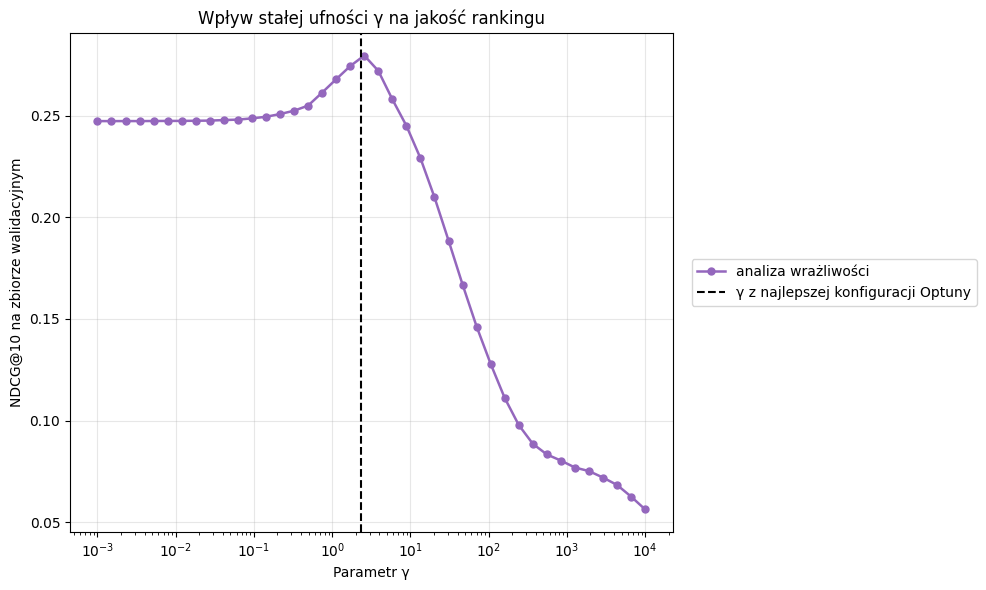

Zapisano: D:\Studiowe\Licencjat\modele\figures\wrazliwosc_constant_ndcg_vs_gamma.png


In [24]:
# =========================
# WYKRES: WRAŻLIWOŚĆ NA GAMMA
# =========================

import matplotlib.pyplot as plt

figures_dir = os.path.join(str(project_path("results/figures")))
os.makedirs(figures_dir, exist_ok=True)

function_colors = {
    "constant": "tab:purple",
    "linear": "tab:blue",
    "log": "tab:orange",
    "log_saturation": "tab:red",
    "log_inside_beta": "tab:green",
}

gamma_df = gamma_sensitivity_df.sort_values("gamma").reset_index(drop=True)

constant_best = best_configs[
    best_configs["function"] == "constant"
].iloc[0]

best_gamma = float(constant_best["gamma"])

plt.figure(figsize=(10, 6))

plt.plot(
    gamma_df["gamma"],
    gamma_df["validation_ndcg@10"],
    marker="o",
    linewidth=1.8,
    markersize=5,
    color=function_colors["constant"],
    label="analiza wrażliwości",
)

plt.axvline(
    best_gamma,
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="γ z najlepszej konfiguracji Optuny",
)

plt.xscale("log")
plt.xlabel("Parametr γ")
plt.ylabel("NDCG@10 na zbiorze walidacyjnym")
plt.title("Wpływ stałej ufności γ na jakość rankingu")

plt.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
)

plt.grid(True, alpha=0.3)
plt.tight_layout()

path = os.path.join(
    figures_dir,
    "wrazliwosc_constant_ndcg_vs_gamma.png"
)

plt.savefig(path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Zapisano: {path}")

In [26]:
# =========================
# PODSUMOWANIE WSZYSTKICH WYNIKÓW
# =========================

import os
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)



optuna_results_dir     = os.path.join(str(project_path("results/optuna")))
final_results_dir      = os.path.join(str(project_path("results/final")))
validation_results_dir = os.path.join(str(project_path("results/validation")))
sensitivity_results_dir = os.path.join(str(project_path("results/sensitivity")))

K = 10


def section(title):
    print("\n" + "=" * 70)
    print(title)
    print("=" * 70)


def load(path):
    if not os.path.exists(path):
        print(f"[BRAK PLIKU] {path}")
        return None
    return pd.read_csv(path)


# =========================
# 1. NAJLEPSZE KONFIGURACJE (OPTUNA)
# =========================

section("1. NAJLEPSZE HIPERPARAMETRY — walidacja Optuny")

best_configs = load(os.path.join(optuna_results_dir, "best_als_configs.csv"))

if best_configs is not None:
    display(
        best_configs.sort_values("validation_ndcg", ascending=False)
        .reset_index(drop=True)
    )


# =========================
# 2. STABILNOŚĆ WZGLĘDEM PODZIAŁÓW DANYCH
# =========================

section("2. STABILNOŚĆ — 5 losowych podziałów train/val (model_random_state=0)")

val_summary = load(
    os.path.join(validation_results_dir, "validation_stability_summary.csv")
)

if val_summary is not None:
    cols = ["model", "function_label", "n_splits"] + [
        c for c in val_summary.columns
        if c.startswith((f"ndcg@{K}", f"recall@{K}", f"coverage@{K}"))
    ]
    display(val_summary[cols])

    print("\nRanking wg NDCG@10 (walidacja):")
    display(
        val_summary[["model", f"ndcg@{K}_mean", f"ndcg@{K}_std"]]
        .sort_values(f"ndcg@{K}_mean", ascending=False)
        .reset_index(drop=True)
    )


# =========================
# 3. WYNIKI NA ZBIORZE TESTOWYM
# =========================

section("3. ZBIÓR TESTOWY — 5 seedów modelu, mean ± std")

test_pretty = load(os.path.join(final_results_dir, "test_summary_pretty.csv"))
test_summary = load(os.path.join(final_results_dir, "test_summary.csv"))

if test_pretty is not None:
    display(test_pretty)

if test_summary is not None:
    print("\nRanking wg NDCG@10 (test):")
    display(
        test_summary[["model", f"ndcg@{K}_mean", f"ndcg@{K}_std"]]
        .sort_values(f"ndcg@{K}_mean", ascending=False)
        .reset_index(drop=True)
    )


# =========================
# 4. TESTY WILCOXONA
# =========================

section("4. TESTY WILCOXONA — pary wariantów, korekta Holma")

wilcoxon_results = load(
    os.path.join(final_results_dir, "wilcoxon_holm_results.csv")
)

if wilcoxon_results is not None:
    print(f"Liczba porównań w rodzinie: {len(wilcoxon_results)}")
    print(f"Liczba użytkowników: {wilcoxon_results['n_users'].iloc[0]}")

    display(
        wilcoxon_results[
            [
                "comparison",
                "median_difference_b_minus_a",
                "p_value_raw",
                "p_value_holm",
                "significant_0.05",
            ]
        ]
    )

    n_sig = int(wilcoxon_results["significant_0.05"].sum())
    print(f"\nIstotnych po korekcie Holma: {n_sig} / {len(wilcoxon_results)}")

    if n_sig > 0:
        print("\nIstotne porównania:")
        display(
            wilcoxon_results[wilcoxon_results["significant_0.05"]][
                ["comparison", "median_difference_b_minus_a", "p_value_holm"]
            ]
        )

pval_matrix = load(
    os.path.join(final_results_dir, "wilcoxon_holm_pvalue_matrix.csv")
)

if pval_matrix is not None:
    print("\nMacierz p-wartości po korekcie Holma:")
    display(pval_matrix.set_index(pval_matrix.columns[0]).round(4))


# =========================
# 5. ANALIZA WRAŻLIWOŚCI
# =========================

section("5. ANALIZA WRAŻLIWOŚCI")

for label, filename, param in [
    ("alpha (wszystkie funkcje)", "sensitivity_alpha_mean_signal.csv", "alpha"),
    ("beta (log_inside_beta)",    "sensitivity_beta_log_inside.csv",   "beta"),
    ("gamma (constant)",          "sensitivity_gamma_constant.csv",    "gamma"),
]:
    df = load(os.path.join(sensitivity_results_dir, filename))

    if df is None:
        continue

    print(f"\n--- {label} ---")
    print(f"Punktów w siatce: {len(df)}")
    print(
        f"Zakres {param}: "
        f"{df[param].min():.3e} → {df[param].max():.3e}"
    )
    print(
        f"NDCG@10: min={df['validation_ndcg@10'].min():.4f}, "
        f"max={df['validation_ndcg@10'].max():.4f}, "
        f"rozpiętość={df['validation_ndcg@10'].max() - df['validation_ndcg@10'].min():.4f}"
    )

    print("Najlepsze 5 punktów:")
    display(
        df.sort_values("validation_ndcg@10", ascending=False)
        .head(5)
        .reset_index(drop=True)
    )


# =========================
# 6. SANITY CHECK
# =========================

section("6. SANITY CHECK — spójność między etapami")

test_metrics = load(os.path.join(final_results_dir, "test_metrics_by_seed.csv"))
val_metrics = load(
    os.path.join(validation_results_dir, "validation_metrics_by_split.csv")
)

if test_metrics is not None:
    print("Wierszy na model (test, oczekiwane 5):")
    print(test_metrics["model"].value_counts().to_string())

    print("\nLiczba ocenionych użytkowników na model (powinna być identyczna):")
    print(test_metrics.groupby("model")["users_evaluated"].unique().to_string())

if val_metrics is not None:
    print("\nWierszy na model (walidacja, oczekiwane 5):")
    print(val_metrics["model"].value_counts().to_string())

print("\n" + "=" * 70)
print("KONIEC PODSUMOWANIA")
print("=" * 70)


1. NAJLEPSZE HIPERPARAMETRY — walidacja Optuny


,model,function,factors,iterations,alpha,beta,gamma,regularization,validation_ndcg,study_name,n_trials
0,ALS-constant,constant,48,30,1.000000e+00,NaN,2.364168,0.057607,0.280063,als_constant,150
1,ALS-log-inside-beta,log_inside_beta,48,30,3.891845e-01,108.283984,NaN,0.010565,0.275349,als_log_inside_beta,150
2,ALS-log-saturation,log_saturation,24,30,2.439038e-02,NaN,NaN,0.169714,0.261400,als_log_saturation,150
3,ALS-log,log,24,30,5.713901e-04,NaN,NaN,0.130920,0.261320,als_log,150
4,ALS-linear,linear,80,30,9.948124e-07,NaN,NaN,0.003588,0.248913,als_linear,150



2. STABILNOŚĆ — 5 losowych podziałów train/val (model_random_state=0)


,model,function_label,n_splits,recall@10_mean,recall@10_std,ndcg@10_mean,ndcg@10_std,coverage@10_mean,coverage@10_std
0,Popular,popularność,5,0.171887,0.000154,0.161510,0.000418,0.006893,0.000212
1,ALS-constant,stała (γ),5,0.300661,0.001032,0.279243,0.000712,0.120811,0.000617
2,ALS-linear,liniowa,5,0.230156,0.000769,0.246587,0.001131,0.102525,0.000332
3,ALS-log,logarytmiczna,5,0.258902,0.001855,0.253402,0.001784,0.063602,0.000629
4,ALS-log-saturation,logarytmiczna z saturacją,5,0.259591,0.001519,0.253627,0.001528,0.063537,0.000601
5,ALS-log-inside-beta,logarytmiczna z przesunięciem β,5,0.296298,0.001155,0.274389,0.001147,0.113766,0.001699



Ranking wg NDCG@10 (walidacja):


...


--- beta (log_inside_beta) ---
Punktów w siatce: 40
Zakres beta: 1.000e+00 → 1.000e+06
NDCG@10: min=0.2427, max=0.2775, rozpiętość=0.0347
Najlepsze 5 punktów:


,model,function,alpha,beta,factors,iterations,regularization,validation_ndcg@10,mean_signal_strength
0,ALS-log-inside-beta,log_inside_beta,0.389185,587.801607,48,30,0.010565,0.277468,3.638188
1,ALS-log-inside-beta,log_inside_beta,0.389185,412.462638,48,30,0.010565,0.277412,3.532665
2,ALS-log-inside-beta,log_inside_beta,0.389185,837.677640,48,30,0.010565,0.277318,3.747950
3,ALS-log-inside-beta,log_inside_beta,0.389185,289.426612,48,30,0.010565,0.277162,3.431575
4,ALS-log-inside-beta,log_inside_beta,0.389185,1193.776642,48,30,0.010565,0.276983,3.861695



--- gamma (constant) ---
Punktów w siatce: 40
Zakres gamma: 1.000e-03 → 1.000e+04
NDCG@10: min=0.0562, max=0.2797, rozpiętość=0.2234
Najlepsze 5 punktów:


,model,function,alpha,gamma,factors,iterations,regularization,gamma_over_reg,validation_ndcg@10,mean_signal_strength
0,ALS-constant,constant,1.0,2.571914,48,30,0.057607,44.645567,0.279667,3.571914
1,ALS-constant,constant,1.0,1.701254,48,30,0.057607,29.531884,0.274470,2.701254
2,ALS-constant,constant,1.0,3.888155,48,30,0.057607,67.494054,0.272126,4.888155
3,ALS-constant,constant,1.0,1.125336,48,30,0.057607,19.534576,0.268006,2.125336
4,ALS-constant,constant,1.0,0.744380,48,30,0.057607,12.921615,0.261425,1.744380



6. SANITY CHECK — spójność między etapami
Wierszy na model (test, oczekiwane 5):
model
ALS-linear             5
ALS-log                5
ALS-log-saturation     5
ALS-log-inside-beta    5
ALS-constant           5
Popular                1

Liczba ocenionych użytkowników na model (powinna być identyczna):
model
ALS-constant           [62944]
ALS-linear             [62944]
ALS-log                [62944]
ALS-log-inside-beta    [62944]
ALS-log-saturation     [62944]
Popular                [62944]

Wierszy na model (walidacja, oczekiwane 5):
model
ALS-linear             5
ALS-log                5
ALS-log-saturation     5
ALS-log-inside-beta    5
Popular                5
ALS-constant           5

KONIEC PODSUMOWANIA


In [27]:
# =========================
# EKSPORT WYNIKÓW DO WKLEJENIA (czysty tekst)
# =========================

import os
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)
pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda x: f"{x:.6g}")



optuna_results_dir      = os.path.join(str(project_path("results/optuna")))
final_results_dir       = os.path.join(str(project_path("results/final")))
validation_results_dir  = os.path.join(str(project_path("results/validation")))
sensitivity_results_dir = os.path.join(str(project_path("results/sensitivity")))

K = 10

out = []


def add(text=""):
    out.append(str(text))


def add_df(df, max_rows=None):
    if df is None:
        add("[BRAK DANYCH]")
        return
    if max_rows is not None and len(df) > max_rows:
        add(df.head(max_rows).to_string(index=False))
        add(f"... ({len(df) - max_rows} dalszych wierszy pominięto)")
    else:
        add(df.to_string(index=False))


def section(title):
    add()
    add("=" * 78)
    add(title)
    add("=" * 78)


def load(path):
    if not os.path.exists(path):
        return None
    return pd.read_csv(path)


# =========================
# 1. NAJLEPSZE KONFIGURACJE
# =========================

section("1. NAJLEPSZE HIPERPARAMETRY (Optuna, NDCG@10 na walidacji)")

best_configs = load(os.path.join(optuna_results_dir, "best_als_configs.csv"))
add_df(
    best_configs.sort_values("validation_ndcg", ascending=False)
    if best_configs is not None else None
)


# =========================
# 2. STABILNOŚĆ — PODZIAŁY DANYCH
# =========================

section("2. STABILNOSC WZGLEDEM PODZIALOW TRAIN/VAL (5 podzialow)")

val_summary = load(
    os.path.join(validation_results_dir, "validation_stability_summary.csv")
)

if val_summary is not None:
    keep = ["model", "function", "n_splits"]
    for m in ["precision", "recall", "ndcg", "coverage", "delta_gap", "diversity"]:
        for suffix in ["mean", "std"]:
            col = f"{m}@{K}_{suffix}"
            if col in val_summary.columns:
                keep.append(col)
    add_df(val_summary[keep])
else:
    add("[BRAK DANYCH]")


# =========================
# 3. ZBIÓR TESTOWY
# =========================

section("3. ZBIOR TESTOWY (5 seedow modelu, mean +/- std)")

test_summary = load(os.path.join(final_results_dir, "test_summary.csv"))

if test_summary is not None:
    keep = ["model", "function", "n_runs"]
    for m in ["precision", "recall", "ndcg", "coverage", "delta_gap", "diversity"]:
        for suffix in ["mean", "std"]:
            col = f"{m}@{K}_{suffix}"
            if col in test_summary.columns:
                keep.append(col)
    if "users_evaluated_mean" in test_summary.columns:
        keep.append("users_evaluated_mean")
    add_df(test_summary[keep])
else:
    add("[BRAK DANYCH]")

add()
add("--- surowe wyniki per seed (NDCG@10) ---")

test_metrics = load(os.path.join(final_results_dir, "test_metrics_by_seed.csv"))

if test_metrics is not None:
    pivot = test_metrics.pivot_table(
        index="model", columns="seed", values=f"ndcg@{K}"
    )
    add_df(pivot.reset_index())
else:
    add("[BRAK DANYCH]")


# =========================
# 4. WILCOXON
# =========================

section("4. TESTY WILCOXONA (korekta Holma)")

wilcoxon_results = load(
    os.path.join(final_results_dir, "wilcoxon_holm_results.csv")
)

if wilcoxon_results is not None:
    add(f"Liczba porownan: {len(wilcoxon_results)}")
    add(f"Liczba uzytkownikow: {wilcoxon_results['n_users'].iloc[0]}")
    add(
        f"Istotnych po Holmie: "
        f"{int(wilcoxon_results['significant_0.05'].sum())} / {len(wilcoxon_results)}"
    )
    add()
    add_df(
        wilcoxon_results[
            [
                "comparison",
                "n_users",
                "wilcoxon_statistic",
                "median_difference_b_minus_a",
                "mean_difference_b_minus_a",
                "model_a_mean_ndcg",
                "model_b_mean_ndcg",
                "p_value_raw",
                "p_value_holm",
                "significant_0.05",
            ]
        ]
    )
else:
    add("[BRAK DANYCH]")


# =========================
# 5. WRAŻLIWOŚĆ
# =========================

section("5. ANALIZA WRAZLIWOSCI")

for label, filename, param in [
    ("GAMMA (ALS-constant)",       "sensitivity_gamma_constant.csv",    "gamma"),
    ("BETA (log_inside_beta)",     "sensitivity_beta_log_inside.csv",   "beta"),
    ("ALPHA (wszystkie funkcje)",  "sensitivity_alpha_mean_signal.csv", "alpha"),
]:
    df = load(os.path.join(sensitivity_results_dir, filename))

    add()
    add(f"--- {label} ---")

    if df is None:
        add("[BRAK DANYCH]")
        continue

    ndcg_col = "validation_ndcg@10"

    add(f"Punktow: {len(df)}")
    add(f"Zakres {param}: {df[param].min():.4g} -> {df[param].max():.4g}")
    add(
        f"NDCG@10: min={df[ndcg_col].min():.4f}  "
        f"max={df[ndcg_col].max():.4f}  "
        f"rozpietosc={df[ndcg_col].max() - df[ndcg_col].min():.4f}"
    )
    add()

    # dla gamma i beta: cała siatka (40 punktów), dla alphy tylko top
    if param in ("gamma", "beta"):
        cols = [c for c in [param, "mean_signal_strength", "gamma_over_reg", ndcg_col]
                if c in df.columns]
        add_df(df.sort_values(param)[cols])
    else:
        cols = [c for c in ["function", param, "mean_signal_strength", ndcg_col]
                if c in df.columns]
        add("Najlepsze 3 punkty na funkcje:")
        add_df(
            df.sort_values(ndcg_col, ascending=False)
            .groupby("function")
            .head(3)
            .sort_values(["function", ndcg_col], ascending=[True, False])[cols]
        )


# =========================
# 6. SANITY CHECK
# =========================

section("6. SANITY CHECK")

if test_metrics is not None:
    add("Wierszy na model (test, oczekiwane 5):")
    add(test_metrics["model"].value_counts().to_string())
    add()
    add("users_evaluated na model (powinno byc identyczne):")
    add(test_metrics.groupby("model")["users_evaluated"].unique().to_string())

val_metrics = load(
    os.path.join(validation_results_dir, "validation_metrics_by_split.csv")
)

if val_metrics is not None:
    add()
    add("Wierszy na model (walidacja, oczekiwane 5):")
    add(val_metrics["model"].value_counts().to_string())


# =========================
# WYDRUK
# =========================

report = "\n".join(out)

print(report)

report_path = os.path.join(str(project_path("results/podsumowanie_wynikow.txt")))
with open(report_path, "w", encoding="utf-8") as f:
    f.write(report)

print(f"\n\n[Zapisano rowniez do: {report_path}]")


1. NAJLEPSZE HIPERPARAMETRY (Optuna, NDCG@10 na walidacji)
              model        function  factors  iterations       alpha    beta   gamma  regularization  validation_ndcg          study_name  n_trials
       ALS-constant        constant       48          30           1     NaN 2.36417       0.0576074         0.280063        als_constant       150
ALS-log-inside-beta log_inside_beta       48          30    0.389185 108.284     NaN       0.0105655         0.275349 als_log_inside_beta       150
 ALS-log-saturation  log_saturation       24          30   0.0243904     NaN     NaN        0.169714           0.2614  als_log_saturation       150
            ALS-log             log       24          30  0.00057139     NaN     NaN         0.13092          0.26132             als_log       150
         ALS-linear          linear       80          30 9.94812e-07     NaN     NaN      0.00358789         0.248913          als_linear       150

2. STABILNOSC WZGLEDEM PODZIALOW TRAIN/VAL (5 podzi

In [2]:
# =========================
# WIELKOŚĆ EFEKTU + PAIRED BOOTSTRAP CI
# =========================

import numpy as np
import pandas as pd
import itertools
from tqdm.auto import tqdm

import os

final_results_dir = os.path.join(str(project_path("results/final")))

per_user_ndcg_path = os.path.join(final_results_dir, "per_user_ndcg.csv")

rng = np.random.default_rng(42)

N_BOOT = 5000
K = 10
ndcg_col = f"ndcg@{K}"

als_functions = ["linear", "log", "log_saturation", "log_inside_beta", "constant"]

per_user_df = pd.read_csv(per_user_ndcg_path)
per_user_df["user_id"] = per_user_df["user_id"].astype(str)

als_df = per_user_df[per_user_df["function"].isin(als_functions)]

# uśrednienie po ziarnach — seed nie jest niezależną obserwacją użytkownika
per_user_mean = (
    als_df.groupby(["function", "user_id"], as_index=False)[ndcg_col].mean()
)

M = per_user_mean.pivot(
    index="user_id", columns="function", values=ndcg_col
).dropna(subset=als_functions)

n_users = len(M)
print(f"Użytkowników: {n_users}")

# wspólne indeksy bootstrapowe dla wszystkich par
boot_idx = rng.integers(0, n_users, size=(N_BOOT, n_users), dtype=np.int32)

rows = []

for a, b in tqdm(list(itertools.combinations(als_functions, 2))):
    diff = (M[b] - M[a]).values          # dodatnie = b lepszy

    boot_means = diff[boot_idx].mean(axis=1)
    lo, hi = np.percentile(boot_means, [2.5, 97.5])

    n_pos = int((diff > 0).sum())
    n_neg = int((diff < 0).sum())
    n_zero = int((diff == 0).sum())

    rows.append({
        "para": f"{a} vs {b}",
        "mediana": float(np.median(diff)),
        "srednia": float(diff.mean()),
        "ci_lo": float(lo),
        "ci_hi": float(hi),
        "pct_remisow": 100 * n_zero / n_users,
        "win_rate_b": 100 * n_pos / (n_pos + n_neg),
    })

effects = pd.DataFrame(rows).sort_values("srednia", key=abs, ascending=False)

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
display(effects)

# wiersze gotowe do LaTeXa
print()
for _, r in effects.iterrows():
    print(
        f"{r['para']} & ${r['mediana']:.4f}$ & ${r['srednia']:+.4f}$ & "
        f"$[{r['ci_lo']:+.4f}, {r['ci_hi']:+.4f}]$ & "
        f"${r['pct_remisow']:.1f}\\%$ \\\\"
    )

Użytkowników: 62944


  0%|          | 0/10 [00:00<?, ?it/s]

,para,mediana,srednia,ci_lo,ci_hi,pct_remisow,win_rate_b
3,linear vs constant,0.0000,0.0266,0.0248,0.0284,16.0984,49.3515
2,linear vs log_inside_beta,0.0000,0.0218,0.0200,0.0236,15.7394,48.4266
8,log_saturation vs constant,0.0000,0.0211,0.0200,0.0222,20.6660,55.9656
6,log vs constant,0.0000,0.0209,0.0198,0.0221,20.6358,55.8703
7,log_saturation vs log_inside_beta,0.0000,0.0163,0.0151,0.0174,20.0639,54.4529
5,log vs log_inside_beta,0.0000,0.0161,0.0149,0.0172,20.0512,54.4026
0,linear vs log,0.0000,0.0057,0.0036,0.0078,16.8181,47.1313
1,linear vs log_saturation,0.0000,0.0055,0.0034,0.0076,16.7736,47.1195
9,log_inside_beta vs constant,0.0000,0.0049,0.0045,0.0052,24.0293,55.4863
4,log vs log_saturation,0.0000,-0.0002,-0.0003,-0.0001,67.1486,46.9194



linear vs constant & $0.0000$ & $+0.0266$ & $[+0.0248, +0.0284]$ & $16.1\%$ \\
linear vs log_inside_beta & $0.0000$ & $+0.0218$ & $[+0.0200, +0.0236]$ & $15.7\%$ \\
log_saturation vs constant & $0.0000$ & $+0.0211$ & $[+0.0200, +0.0222]$ & $20.7\%$ \\
log vs constant & $0.0000$ & $+0.0209$ & $[+0.0198, +0.0221]$ & $20.6\%$ \\
log_saturation vs log_inside_beta & $0.0000$ & $+0.0163$ & $[+0.0151, +0.0174]$ & $20.1\%$ \\
log vs log_inside_beta & $0.0000$ & $+0.0161$ & $[+0.0149, +0.0172]$ & $20.1\%$ \\
linear vs log & $0.0000$ & $+0.0057$ & $[+0.0036, +0.0078]$ & $16.8\%$ \\
linear vs log_saturation & $0.0000$ & $+0.0055$ & $[+0.0034, +0.0076]$ & $16.8\%$ \\
log_inside_beta vs constant & $0.0000$ & $+0.0049$ & $[+0.0045, +0.0052]$ & $24.0\%$ \\
log vs log_saturation & $0.0000$ & $-0.0002$ & $[-0.0003, -0.0001]$ & $67.1\%$ \\


In [3]:
# =========================
# STRUKTURA ZEROWYCH RÓŻNIC
# =========================

pairs_to_check = [
    ("log_inside_beta", "constant"),
    ("linear", "constant"),
    ("log", "log_saturation"),
]

# odsetek użytkowników z NDCG = 0 w każdym wariancie osobno
print("Użytkownicy z NDCG@10 = 0:")
for fn in als_functions:
    z = (M[fn] == 0).sum()
    print(f"  {fn:18s} {z:6d}  ({100*z/len(M):.1f}%)")

print()

for a, b in pairs_to_check:
    va, vb = M[a].values, M[b].values
    diff = vb - va

    both_zero = int(((va == 0) & (vb == 0)).sum())
    tie_nonzero = int(((va == vb) & (va > 0)).sum())
    differ = int((va != vb).sum())

    print(f"{a} vs {b}:")
    print(f"  oba zero:        {both_zero:6d}  ({100*both_zero/len(M):.1f}%)")
    print(f"  remis niezerowy: {tie_nonzero:6d}  ({100*tie_nonzero/len(M):.1f}%)")
    print(f"  różnią się:      {differ:6d}  ({100*differ/len(M):.1f}%)")
    print()

Użytkownicy z NDCG@10 = 0:
  linear              15343  (24.4%)
  log                 12493  (19.8%)
  log_saturation      12470  (19.8%)
  log_inside_beta      9319  (14.8%)
  constant             9323  (14.8%)

log_inside_beta vs constant:
  oba zero:          8685  (13.8%)
  remis niezerowy:   6440  (10.2%)
  różnią się:       47819  (76.0%)

linear vs constant:
  oba zero:          7376  (11.7%)
  remis niezerowy:   2757  (4.4%)
  różnią się:       52811  (83.9%)

log vs log_saturation:
  oba zero:         12410  (19.7%)
  remis niezerowy:  29856  (47.4%)
  różnią się:       20678  (32.9%)

